#P0

In [55]:
import sys
import tensorflow as tf
import numpy as np
import matplotlib as plt
from tensorflow.keras.datasets import mnist


print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.__version__)

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
TensorFlow version: 2.20.0
NumPy version: 2.1.3
Matplotlib version: 3.10.0


In [56]:
(train_X, train_y), (test_X, test_y) = mnist.load_data()

print('X_train:', train_X.shape)
print('Y_train:', train_y.shape)
print('X_test: ', test_X.shape)
print('Y_test: ', test_y.shape)

X_train: (60000, 28, 28)
Y_train: (60000,)
X_test:  (10000, 28, 28)
Y_test:  (10000,)


In [57]:
mask_filter = np.isin(train_y, [0,1,9])
filtered_images= train_X[mask_filter] #filter images
filtered_labels= train_y[mask_filter] #filter labels
N= mask_filter.sum() #total number of retained images
np.unique(filtered_labels)
print(mask_filter)
print(mask_filter.shape)
print(N)
print(mask_filter.sum()) #number of images that equals 0,1, or 9
print(filtered_images.shape)
print(filtered_labels.shape)





[False  True False ... False False False]
(60000,)
18614
18614
(18614, 28, 28)
(18614,)


In [58]:
images_converted_32= filtered_images.astype(np.float32) #change images from uint8 to float 32
print(images_converted_32.shape)
print(images_converted_32.dtype)

(18614, 28, 28)
float32


In [59]:
images_converted_64= filtered_images.astype(np.float64) #change images from float32 to float 64
print(images_converted_64.shape)
print(images_converted_64.dtype)

(18614, 28, 28)
float64


In [60]:
reshaped_images = images_converted_64.reshape(N,-1) #flatten the images, let numpy figure out how many pixels
print(reshaped_images.shape)

(18614, 784)


In [61]:
images_transpose = reshaped_images.T #get the transpose so they are all rows of X
print(images_transpose.shape)

(784, 18614)


In [62]:
mu= images_transpose.mean(axis=1,keepdims=True) # get the mean of all the images
centred = images_transpose - mu #this is X~
print(centred.shape)
row_sum= centred.sum(axis=1,keepdims=True)
absolute = np.abs(row_sum) #get rid of all the signs for absolute
absolute_max = row_sum.max() #get the max absolute value
print(absolute_max) #its approximately zero!


(784, 18614)
2.1574436459559365e-08


# P1

**{0}**

In [63]:
#build a mask for the zeroes first, because we are getting averages for each class
zeroes_filter= np.isin(filtered_labels, [0])
zeroes_sum= zeroes_filter.sum() #this is N_c
print(zeroes_sum)
#pull the zeroes out of X~
zeroes_images= centred[:,zeroes_filter] #filter the zeroes from X~
print(zeroes_images.shape) #shape of all zeroes in X~
m_c0 = zeroes_images.mean(axis=1) #mean of all zeroes in X~
print(m_c0.shape) #this is shape of m_0
#now lets compute norms
zeroes_m_c1=np.linalg.norm(m_c0,ord=1) #norm1
print(zeroes_m_c1)
zeroes_m_c2=np.linalg.norm(m_c0,ord=2) #norm2
print(zeroes_m_c2)
zeroes_m_c3=np.linalg.norm(m_c0,ord=3) #norm3
print(zeroes_m_c3)

5923
(784, 5923)
(784,)
18400.980056828892
1116.4841028055296
464.5650324385604


**{1}**

In [64]:
#build a mask for the ones next, because we are getting averages for each class
ones_filter= np.isin(filtered_labels, [1])
ones_sum= ones_filter.sum()
print(ones_sum)
#pull the ones out of X~
ones_images= centred[:,ones_filter] #filter the ones from X~
print(ones_images.shape) #shape of all ones in X~
m_c1 = ones_images.mean(axis=1) #mean of all ones in X~ (Nc)
print(m_c1.shape) #this is shape of m_0
#now lets calculate norms
ones_mc_1=np.linalg.norm(m_c1,ord=1) #norm1
print(ones_mc_1)
ones_m_c2=np.linalg.norm(m_c1,ord=2) #norm2
print(ones_m_c2)
ones_m_c3=np.linalg.norm(m_c1,ord=3) #norm3
print(ones_m_c3)


6742
(784, 6742)
(784,)
14909.458531817245
936.2123937863066
397.48027158304205


**{9}**

In [65]:
#build a mask for the nines next, because we are getting averages for each class
nines_filter= np.isin(filtered_labels, [9])
nines_sum= nines_filter.sum()
print(nines_sum)
#pull the nines out of X~
nines_images= centred[:,nines_filter] #filter the nines from X~
print(nines_images.shape) #shape of all nines in X~
m_c9 = nines_images.mean(axis=1) #mean of all nines in X~ (Nc)
print(m_c9.shape) #this is shape of m_0
#now lets calculate norms
nines_m_c1=np.linalg.norm(m_c9,ord=1) #norm1
print(nines_m_c1)
nines_m_c2=np.linalg.norm(m_c9,ord=2) #norm2
print(nines_m_c2)
nines_m_c3=np.linalg.norm(m_c9,ord=3) #norm3
print(nines_m_c3)

5949
(784, 5949)
(784,)
11648.197980323901
749.0003585509057
334.0444442899656


# P2

In [66]:
svd_U,svd_sigma, svd_vT = np.linalg.svd(centred, full_matrices=False) #calculate the SVD
svd_top_ten= svd_sigma[:10] #get the top 10 singular values
svd_bottom_ten= svd_sigma[-10:] #get the bottom 10 singular values
print(svd_U.shape)
print(svd_sigma.shape)
print(svd_vT.shape)
print(svd_top_ten)
print(svd_bottom_ten)


(784, 784)
(784,)
(784, 18614)
[117661.83011205  79807.84031516  66057.52625675  61018.07463916
  46559.6782754   45136.83808256  42616.87931615  39474.67343566
  36525.72314041  33354.01782727]
[8.18868107e-12 8.18868107e-12 8.18868107e-12 8.18868107e-12
 6.17571998e-12 4.77538815e-12 4.51014526e-12 2.80395905e-12
 1.33939039e-12 8.47534359e-13]


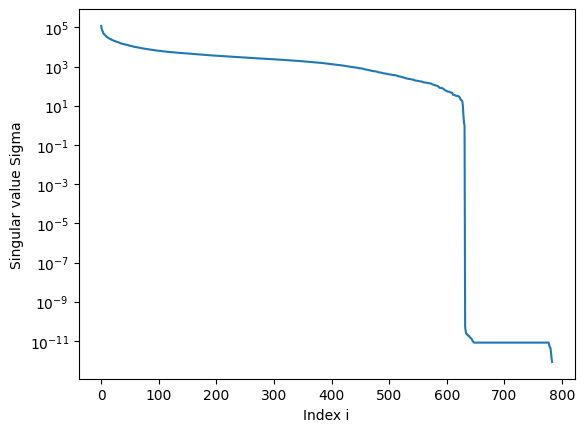

In [67]:
#now lets plot
import matplotlib.pyplot as plt
plt.semilogy(svd_sigma) #we need semilogy because plt.plot just shows the curve without the tail detail at the end
plt.xlabel('Index i')
plt.ylabel('Singular value Sigma')
plt.show()

In [68]:
#now lets get tolerance
e_mach = np.finfo(np.float64).eps
print(e_mach)
print(svd_sigma[0])
tolerance = 18614 * e_mach * svd_sigma[0]
print(tolerance)

#now lets see how many values are above the tolerance (r)
above_tolerance = svd_sigma >tolerance
r = above_tolerance.sum()
print(r)

#calculate sigma_r
sigma_r = svd_sigma[631]
print(sigma_r)




2.220446049250313e-16
117661.8301120451
4.863126136690726e-07
632
0.9345471928526435


In [69]:
#compute the cumulative energy
svd_sigma_squared = svd_sigma **2 # this is sigma_i^2, the spread of data along direction i
cumulative_energy = np.cumsum(svd_sigma_squared) / np.sum(svd_sigma_squared)



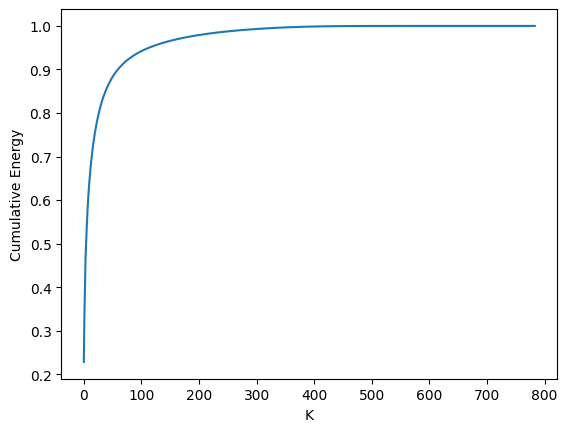

In [70]:
#plot E(K) versus (K)
plt.plot(cumulative_energy)
plt.xlabel('K')
plt.ylabel('Cumulative Energy')
plt.show()

In [71]:
#calculate the three K values (90%, 95%, 99% cumulative energy)
k_90 = np.argmax(cumulative_energy >= 0.90)
print(k_90)
k_95 = np.argmax(cumulative_energy >= 0.95)
print(k_95)
k_99 = np.argmax(cumulative_energy >= 0.99)
print(k_99)

60
114
271


# P3

In [72]:
#create K_set

K_grid = np.arange(1,752,50)
less_than_r = K_grid[K_grid<= r]
add_r= np.append(r,less_than_r) # r is always included
K_set = np.unique(add_r) # remove the duplicate values and sorts
print(K_set) # finaly K_set
print(K_set.shape)



[  1  51 101 151 201 251 301 351 401 451 501 551 601 632]
(14,)


In [108]:
#now we need to define Y_K in a function, since we will be using it later
def get_Y_K(K):
  Q_K = svd_U[:,:K] #lets calculate Q_K, the first K columns of U --> Y_K = Q_KQ_KKTX~.
  Y_K = Q_K @ (Q_K.T @ centred) #Y_K- take all 18,614 images and replace with closest point in K dimensional subspace
  return Y_K
  return Q_K


Y_K_test = get_Y_K(1).shape #test run
print(Y_K_test)
Y_K = get_Y_K(1)


#Q_KTX~ is K x 18,614 , which is the product we would actually store, not Y_K. This is each image described by K coordinates instead of 784 pixels


(784, 18614)


In [74]:
#reconstruct in original image coordinates- compute X^_K= mu1^T + Y_K
X_hat_K = mu + Y_K
print(X_hat_K.shape)

(784, 18614)


In [75]:
#compute the direct centred approximation error at e_K = ||X~ - Y_K||_F at K=1, 100, and 632

X_hat_fro_norm = np.linalg.norm(centred, 'fro')
e_K_1= np.linalg.norm(centred - Y_K,'fro')
e_K_100= np.linalg.norm(centred - get_Y_K(100),'fro')
e_K_632= np.linalg.norm(centred - get_Y_K(632),'fro')
print(X_hat_fro_norm)
print(e_K_1)
print(e_K_100)
print(e_K_632)

246229.4112583112
216297.51894860636
59550.15645580655
3.91266808733981e-10


In [76]:
#compute the SVD-based error for every K in K_set

e_SVD_values = []
for K in K_set:
  sigma_squared = svd_sigma[K:r] **2
  e_SVD_K = np.sqrt(np.sum(sigma_squared))
  e_SVD_values.append(e_SVD_K)

print(e_SVD_values)

#compute e^100_SVD even while not in set K

sigma_squared_100 = svd_sigma[100:r] **2
e_SVD_100 = np.sqrt(np.sum(sigma_squared_100))
print(e_SVD_100)

sigma_squared_1 = svd_sigma[1:r] **2
e_SVD_1 = np.sqrt(np.sum(sigma_squared_1))
print(e_SVD_1)

sigma_squared_r = svd_sigma[r] **2
e_SVD_r = np.sqrt(np.sum(sigma_squared_r))
print(e_SVD_r)




[np.float64(216297.51894860764), np.float64(84171.35715043618), np.float64(59209.52122014554), np.float64(45552.643595899586), np.float64(35586.83946462865), np.float64(27530.360676124295), np.float64(20601.51798996625), np.float64(14357.284011813916), np.float64(8914.274755858261), np.float64(4712.13523693559), np.float64(2233.176508112695), np.float64(914.100797350982), np.float64(198.14044881940833), np.float64(0.0)]
59550.156455806486
216297.51894860764
5.404757903292441e-11


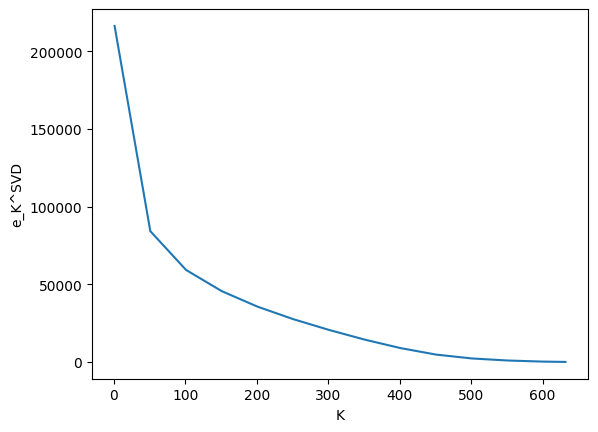

In [77]:
#Figure 3, plot e_K^SVD versus K for K in K_set

plt.plot(K_set, e_SVD_values)
plt.xlabel('K')
plt.ylabel('e_K^SVD')
plt.show()

# P4

In [78]:
#compute the number of stored scalar values required by the full matrix


S_full = centred.shape[0] * centred.shape[1] #N is 18,614 images, and N is the number of all the images
print(S_full)

#compute the low-rank representation

S_LR_K = centred.shape[0] + (centred.shape[0] * K_set) + (K_set * centred.shape[1]) #S_LR_K is basically a count of storage slots
print(S_LR_K.shape)

#compute the storage ratio

p_K = S_LR_K / S_full
print(p_K)

14593376
(14,)
[0.00138296 0.06784462 0.13430628 0.20076794 0.2672296  0.33369126
 0.40015292 0.46661458 0.53307624 0.5995379  0.66599956 0.73246122
 0.79892288 0.84012911]


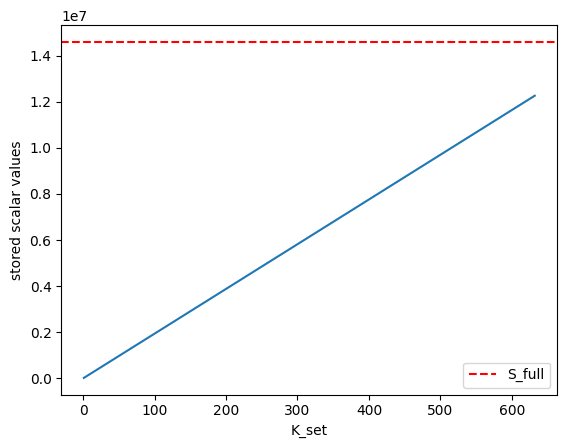

In [79]:
#plot S_LR(K) versus K and include a horizontal reference line at S_full. label the vertical axis in scalar values
plt.plot(K_set, S_LR_K)
plt.xlabel('K_set')
plt.ylabel('stored scalar values')
plt.axhline(y= S_full, color='red', linestyle='--', linewidth=1.5, label='S_full')
plt.legend()
plt.show()

# P5

In [80]:
#project the centred data onto the first two left singular vectors

Q_2 = svd_U[:,:2] #get Q_2
P_2 = Q_2.T @ centred #P_2 = Q_2^T*X~
print(P_2.shape)
print(P_2.min())
print(P_2.max())

#for each class {0,1,9} compute the projected centroid

p_c_0 = P_2[:,zeroes_filter].mean(axis=1) #projected centroid for zeroes
print(p_c_0)

p_c_1 = P_2[:,ones_filter].mean(axis=1) #projected centroid for ones
print(p_c_1)

p_c_9 = P_2[:,nines_filter].mean(axis=1) #projected centroid for nines
print(p_c_9)

(2, 18614)
-2393.6717979645655
1202.8870829327425
[-1077.02499824   264.49678669]
[838.6380017 397.4213961]
[ 121.88967174 -713.73836276]


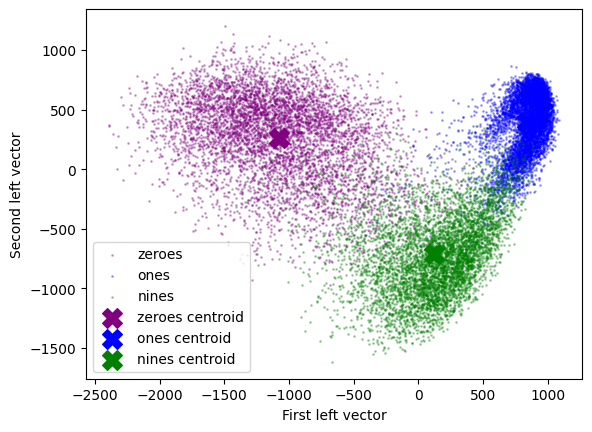

In [81]:
#create a two dimensional scatter plot of the columns of P2, color coded by digit class. Include clearly distinguidshable centroid markers, a legend, and labeled axes

plt.scatter(P_2[0,zeroes_filter], P_2[1,zeroes_filter], color='purple',label='zeroes', s=1, alpha=0.3)
plt.scatter(P_2[0,ones_filter], P_2[1,ones_filter], color='blue', label='ones', s=1, alpha=0.3)
plt.scatter(P_2[0,nines_filter], P_2[1,nines_filter],color='green', label='nines', s=1, alpha=0.3)
plt.scatter(p_c_0[0], p_c_0[1], marker='X', color='purple', label='zeroes centroid',s=200)
plt.scatter(p_c_1[0], p_c_1[1], marker='X', color='blue', label='ones centroid', s=200)
plt.scatter(p_c_9[0], p_c_9[1], marker='X', color='green', label='nines centroid',s=200)
plt.legend()
plt.xlabel('First left vector')
plt.ylabel('Second left vector')
plt.show()

In [82]:
#compute x^_K = mu + Q_KQ_K^T(x-mu)

#select one representative image from each class {0,1,9} , state the zero based index of each selected image in the mnist training split

#create new masks
index_zeroes = np.argmax(train_y == 0)
print(train_y[index_zeroes])
index_ones = np.argmax(train_y == 1)
print(train_y[index_ones])
index_nines = np.argmax(train_y == 9)
print(train_y[index_nines])

print(index_zeroes)
print(index_ones)
print(index_nines)




0
1
9
1
3
4


In [83]:
#compute x^_K = mu + Q_KQ_K^T(x-mu) for K is in {5,20,100}
#zeroes
zeroes_reconstructed = []
ones_reconstructed = []
nines_reconstructed = []
K_recon= [5,20,100]
for k in K_recon:
  Q_k = svd_U[:,:k]
  x_hat_k_zeroes = mu + Q_k @ (Q_k.T @ (centred[:,zeroes_filter][:,0:1]))
  x_hat_k_ones = mu + Q_k @ (Q_k.T @ (centred[:,ones_filter][:,0:1]))
  x_hat_k_nines = mu + Q_k @ (Q_k.T @ (centred[:,nines_filter][:,0:1]))
  zeroes_reconstructed.append(x_hat_k_zeroes)
  ones_reconstructed.append(x_hat_k_ones)
  nines_reconstructed.append(x_hat_k_nines)
  print(x_hat_k_zeroes.shape)
  print(x_hat_k_ones.shape)
  print(x_hat_k_nines.shape)



(784, 1)
(784, 1)
(784, 1)
(784, 1)
(784, 1)
(784, 1)
(784, 1)
(784, 1)
(784, 1)


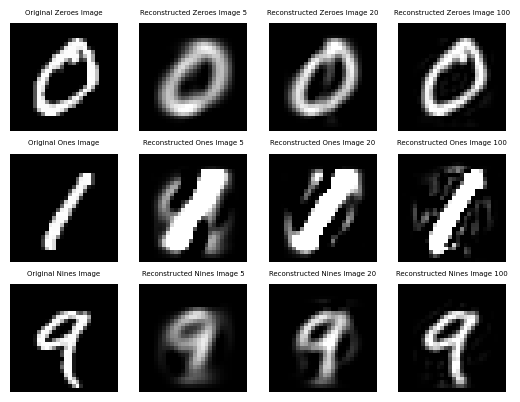

In [84]:

#display each original image and its three reconstructions side by side

zeroes_original = centred[:,zeroes_filter] + mu
ones_original = centred[:,ones_filter] + mu
nines_original = centred[:,nines_filter] + mu

#plot original images
fig,axes = plt.subplots(3,4)
axes[0,0].imshow(zeroes_original[:,0].reshape(28,28), cmap='gray', vmin=0, vmax=255)
axes[0,0].set_title('Original Zeroes Image', size=5)
axes[0,0].axis('off')


axes[1,0].imshow(ones_original[:,0].reshape(28,28), cmap='gray', vmin=0, vmax=255)
axes[1,0].set_title('Original Ones Image', size= 5)
axes[1,0].axis('off')

axes[2,0].imshow(nines_original[:,0].reshape(28,28), cmap='gray', vmin=0, vmax=255)
axes[2,0].set_title('Original Nines Image', size = 5)
axes[2,0].axis('off')

#plot reconstructions - 5
axes[0,1].imshow(zeroes_reconstructed[0].reshape(28,28), cmap='gray', vmin=0, vmax=255)
axes[0,1].set_title('Reconstructed Zeroes Image 5', size=5)
axes[0,1].axis('off')

axes[1,1].imshow(ones_reconstructed[0].reshape(28,28), cmap='gray', vmin=0, vmax=25)
axes[1,1].set_title('Reconstructed Ones Image 5', size=5)
axes[1,1].axis('off')

axes[2,1].imshow(nines_reconstructed[0].reshape(28,28), cmap='gray', vmin=0, vmax=255)
axes[2,1].set_title('Reconstructed Nines Image 5', size=5)
axes[2,1].axis('off')

#plot reconstructions - 20
axes[0,2].imshow(zeroes_reconstructed[1].reshape(28,28), cmap='gray', vmin=0, vmax=255)
axes[0,2].set_title('Reconstructed Zeroes Image 20', size=5)
axes[0,2].axis('off')

axes[1,2].imshow(ones_reconstructed[1].reshape(28,28), cmap='gray', vmin=0, vmax=25)
axes[1,2].set_title('Reconstructed Ones Image 20', size=5)
axes[1,2].axis('off')

axes[2,2].imshow(nines_reconstructed[1].reshape(28,28), cmap='gray', vmin=0, vmax=255)
axes[2,2].set_title('Reconstructed Nines Image 20', size=5)
axes[2,2].axis('off')

#plot reconstructions - 100
axes[0,3].imshow(zeroes_reconstructed[2].reshape(28,28), cmap='gray', vmin=0, vmax=255)
axes[0,3].set_title('Reconstructed Zeroes Image 100', size=5)
axes[0,3].axis('off')

axes[1,3].imshow(ones_reconstructed[2].reshape(28,28), cmap='gray', vmin=0, vmax=25)
axes[1,3].set_title('Reconstructed Ones Image 100', size=5)
axes[1,3].axis('off')

axes[2,3].imshow(nines_reconstructed[2].reshape(28,28), cmap='gray', vmin=0, vmax=255)
axes[2,3].set_title('Reconstructed Nines Image 100', size=5)
axes[2,3].axis('off')


plt.show()






# P6

In [85]:
#rename for ease of use
X= images_transpose.copy()
print(X.shape)
rng = np.random.default_rng(4463)
print(rng)

#corrupt each pixel in X
corruption_mask = rng.random(X.shape) < 0.05 #M_ij ~ Bernoulli(0.05)
salt_mask = rng.random(X.shape) < 0.5 #B_ij(0.5) ~Bernoulli(0.5)

#form the noisy X matrix
X_noisy = X.copy()
X_noisy[corruption_mask] = 0 #pepper
X_noisy[salt_mask & corruption_mask]=255 #salt
print(X_noisy.max())

#centre the noisy matrix using the clean data mean image from problem 0

X_noisy_centred = X_noisy - mu
print(X_noisy_centred.shape)

#for every K in K_set, denoise by projecting onto the subspace learned from the clean, centred data

e_clean_K = []
e_noisy_K = []

for K in K_set:
  Q_K = svd_U[:,:K] #get Q_K, the first K columns of U
  X_hat_nK = mu + Q_K@(Q_K.T @ X_noisy_centred)
  e_clean_K_initial = np.linalg.norm(centred - X_hat_nK, 'fro')
  e_noisy_K_initial = np.linalg.norm(X_noisy - X_hat_nK, 'fro')
  e_baseline = np.linalg.norm(X - mu, 'fro')
  e_clean_K.append(e_clean_K_initial)
  e_noisy_K.append(e_noisy_K_initial)
  #print(f'X_hat_nk shape: {X_hat_nK.shape}')
  #print(f'e_clean_{K}:{e_clean_K}')
  #print(f'e_noisy_{K}: {e_noisy_K}')

print(f'e_baseline: {e_baseline}')
print(e_clean_K)
print(e_noisy_K)

(784, 18614)
Generator(PCG64)
255.0
(784, 18614)
e_baseline: 246229.41125830592
[np.float64(294588.3531408492), np.float64(222490.58057691492), np.float64(217673.13727335163), np.float64(217687.01160487646), np.float64(219055.39820257056), np.float64(221090.5573612974), np.float64(223492.60651276432), np.float64(226137.2585245287), np.float64(229045.5727693176), np.float64(232113.77718733615), np.float64(235291.30427246614), np.float64(238441.50555018504), np.float64(241593.15392081428), np.float64(243511.32138034527)]
[np.float64(254815.7132827097), np.float64(166393.10320386587), np.float64(151873.0684634843), np.float64(142752.31345101705), np.float64(135137.90137303574), np.float64(128113.3092013821), np.float64(121316.71470162994), np.float64(114534.9646404228), np.float64(107503.35585169155), np.float64(100173.71066691741), np.float64(92296.23189624387), np.float64(83778.11411134212), np.float64(74193.25527175881), np.float64(67631.92260445909)]


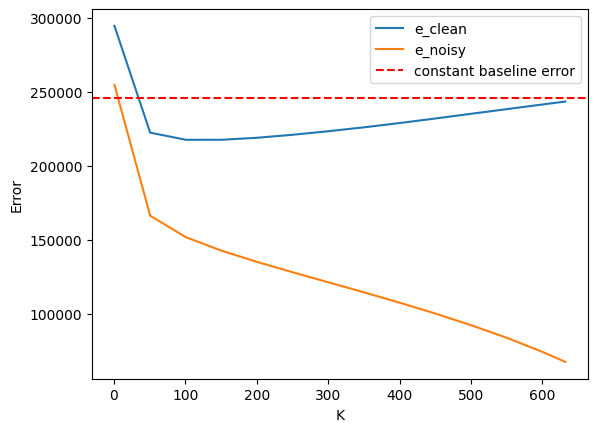

In [86]:
#Fig 7 plot all three errors versus K. Plot e_baseline as a horizontal reference line

plt.plot(K_set, e_clean_K, label='e_clean')
plt.plot(K_set,e_noisy_K, label='e_noisy')
plt.axhline(y= e_baseline, color='red', linestyle='--', linewidth=1.5, label='constant baseline error')
plt.xlabel('K')
plt.ylabel('Error')
plt.legend()
plt.show()

# P7

G= U*sigma*V^T
tolerance_G = 10^-7*sigma_1(G)
r_G = #{i:sigma_i(G)>tolerance_(G)}

report tolerance_G, report r_G, report all singular values of G

for each case, report:

1. The dimensions m × n, all singular values, numerical rank tolerance and numerical rank r_G of G.
2. Whether the system is overdetermined (m > n), square (m = n), or underdetermined (m < n).
3. The numerical entries of P_Range(G). Report ||P_range(G) - P_range(G)^T||_F and ||P_range(G)^2- P_range(G)||_F
4. The projected vector P_Range(G)f and residual. Report r_f= f*P_range(G)f, report ||r_f||_2 and use the prescribed criterion above to determine whether f ∈ Range(G).
5. Whether the system has no exact solution, a unique exact solution, or infnitely many exact solutions. Justify your conclusion using consistency and rank.
6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.
declarations

Cases:

1. G = A, f = y_A

2. G = B, f = y_B

3. G = B, f = y_B2

4. G = C, f = y_C

5. G = C, f = y_C2

6. G = D, f = y_D

7. G = D, f = y_D2

In [99]:


A = np.array([[-2.74125009,  2.24215689, -0.60553211, -0.16755625],
              [-0.34868395,  0.29538923, -0.45259498,  0.50015934],
              [ 2.49664208,  0.27798324,  2.00739274,  0.21978030]])

y_A = np.array([0.61339829, 0.11012282, -0.06426754])

B = np.array([[-2.74125009, -0.34868395,  2.49664208],
              [ 2.24215689,  0.29538923,  0.27798324],
              [-0.60553211, -0.45259498,  2.00739274],
              [-0.16755625,  0.50015934,  0.21978030]])

y_B  = np.array([0.66761214, 0.35931116, 0.74289966, 0.02979187])
y_B2 = np.array([0.24982762, -0.45768269, 0.22778277, 0.63413920])

C = np.array([[0.31997336, 0.43316234, -0.33457014, -0.34017903],
              [1.12969075, 1.52931319, -1.18122581, -1.20102843],
              [0.20087760, 0.27193705, -0.21004138, -0.21356262]])

y_C  = np.array([0.14216640, 0.50192948, 0.08925132])
y_C2 = np.array([-1.01480112, 0.41152110, -0.45229071])

D = np.array([[ 0.07999334,  0.28242269,  0.05021940],
              [ 0.10829058,  0.38232830,  0.06798426],
              [-0.08364254, -0.29530645, -0.05251035],
              [-0.08504476, -0.30025711, -0.05339065]])

y_D  = np.array([0.41615372, 0.56336601, -0.43513813, -0.44243299])
y_D2 = np.array([0.47277025, -0.64357627, 1.30059591, 1.42694800])

eta = 1e-7



#case #1. G = A, f = y_A

In [100]:


#1. The dimensions m × n, all singular values, numerical rank tolerance and numerical rank r_G of G.

#get the dimensions mxn of G

G= A.copy()
print(f' the dimensions mxn of G: {G.shape}') #The dimensions m × n

#get all singular values
SVD_G = np.linalg.svd(G, full_matrices=False)
SVD_U = SVD_G[0]
SVD_sigma = SVD_G[1]
SVD_VT = SVD_G[2]

SVD_U, SVD_sigma, SVD_VT = np.linalg.svd(G, full_matrices=False)
print(f'all singular values of G:{SVD_sigma}') #all singular values

#numerical rank tolerance of G
G_columns = G.shape[1]
e_mach = np.finfo(np.float64).eps
tolerance = G_columns * e_mach * SVD_sigma[0]
print(f'tolerance of G: {tolerance}')

#calculate the rank r_G of G

r_G = np.sum(SVD_sigma > tolerance)
print(f'rank of G: {r_G}') #rank of G

#3. The numerical entries of P_Range(G). Report ||P_range(G) - P_range(G)^T||_F and ||P_range(G)^2- P_range(G)||_F

#calculate P_range(G) = U_r_G @ U_r_G.T
P_range_G = SVD_U[:,:r_G] @ SVD_U[:,:r_G].T
print(f' range of G: {P_range_G}') #range of G

#||P_range(G) - P_range(G)^T||_F <--- calculate symmetric error

symmetric_error = np.linalg.norm(P_range_G - P_range_G.T, 'fro')
print(f'symmetric error: {symmetric_error}')

# ||P_range(G)^2- P_range(G)||_F <--- calculate idempotent error

idempotent_error = np.linalg.norm(P_range_G**2 - P_range_G, 'fro')
print(f'idempotent error: {idempotent_error}')

#4. The projected vector P_Range(G)f and residual.

f= y_A.copy()
print(f'the dimensions of f: {f.shape}')
print(f'the dimensions of G: {G.shape}')

#calculate the projected vector

projected_vector = P_range_G @ f
print(f'projected vector: {projected_vector}')

#calculate the residual

residual = f - projected_vector
print(f'residual: {residual}')

## Report r_f= f-P_range(G)f (the residual norm) which is how far the residual is from the projected vector. use the prescribed criterion above to determine whether f ∈ Range(G)

residual_norm = np.linalg.norm(residual)
print(f'residual norm: {residual_norm}') #inside range of G, basically zero, indicates at least one solution exists


#calculate the l_2 ||r_f||_2 norm which is how far the residual is from the projected vector?

l_2_norm = np.linalg.norm(projected_vector)
print(f'l_2 norm: {l_2_norm}')

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

#If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum-ℓ2-norm solution
#For every pseudoinverse calculation in this problem, use the truncated-SVD pseudoinverse de­fned by the same tolerance:
#G_tolerance.T = V_r_G @ sigma_r_G^-1 @ U_r_G.T

SVD_V= SVD_VT.T
G_pseudoinverse = SVD_V[:,:r_G] @ np.diag(1/SVD_sigma[:r_G]) @ SVD_U[:,:r_G].T
print(f'pseudoinverse: {G_pseudoinverse}')
print(G_pseudoinverse.shape)

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

w = G_pseudoinverse @ f
print(f'w: {w}')
print(w.shape)

#range membership decision

f_norm= (np.linalg.norm(f))
print(f'f_norm:{f_norm}')
f_norm_max = max(f_norm,1)
print(f'f_norm_max: {f_norm_max}')
threshold = eta * f_norm_max
print(f'threshold:{threshold}')

#Justify your conclusion using consistency and rank.

#the matrix is (3,4) which is wide, therefore underdetermined
#the rank is 3, the rank is equal to the number of rows (r=m) which means it is consistent
# the rank is 3, the # of columns is 4, so r<n , n-r = 4-3=1 so there are infinitely many solutions








 the dimensions mxn of G: (3, 4)
all singular values of G:[4.42150234 2.02044244 0.59737377]
tolerance of G: 3.9270829638772965e-15
rank of G: 3
 range of G: [[ 1.00000000e+00  3.48566731e-17 -1.77839740e-16]
 [ 3.48566731e-17  1.00000000e+00  1.65047472e-16]
 [-1.77839740e-16  1.65047472e-16  1.00000000e+00]]
symmetric error: 0.0
idempotent error: 1.3766271442983003e-15
the dimensions of f: (3,)
the dimensions of G: (3, 4)
projected vector: [ 0.61339829  0.11012282 -0.06426754]
residual: [-5.55111512e-16  8.32667268e-17  1.24900090e-16]
residual norm: 5.750497121565129e-16
l_2 norm: 0.6265100273398094
pseudoinverse: [[-0.15325779  0.32016108  0.17899279]
 [ 0.29321061  0.33783661  0.28929374]
 [ 0.16437815 -0.60639144  0.21884222]
 [-0.13126429  1.4743142   0.15196067]]
(4, 3)
w: [-0.07025445  0.19846621  0.01998729  0.07207221]
(4,)
f_norm:0.626510027339809
f_norm_max: 1
threshold:1e-07


## case #2. G = B, f = y_B

In [101]:
#1. The dimensions m × n, all singular values, numerical rank tolerance and numerical rank r_G of G.

#get the dimensions mxn of G

G= B.copy()
print(f' the dimensions mxn of G: {G.shape}') #The dimensions m × n

#get all singular values
SVD_G = np.linalg.svd(G, full_matrices=False)
SVD_U = SVD_G[0]
SVD_sigma = SVD_G[1]
SVD_VT = SVD_G[2]

SVD_U, SVD_sigma, SVD_VT = np.linalg.svd(G, full_matrices=False)
print(f'all singular values of G:{SVD_sigma}') #all singular values

#numerical rank tolerance of G
G_columns = G.shape[1]
e_mach = np.finfo(np.float64).eps
tolerance = G_columns * e_mach * SVD_sigma[0]
print(f'tolerance of G: {tolerance}')

#calculate the rank r_G of G

r_G = np.sum(SVD_sigma > tolerance)
print(f'rank of G: {r_G}') #rank of G

#3. The numerical entries of P_Range(G). Report ||P_range(G) - P_range(G)^T||_F and ||P_range(G)^2- P_range(G)||_F

#calculate P_range(G) = U_r_G @ U_r_G.T
P_range_G = SVD_U[:,:r_G] @ SVD_U[:,:r_G].T
print(f' range of G: {P_range_G}') #range of G

#||P_range(G) - P_range(G)^T||_F <--- calculate symmetric error

symmetric_error = np.linalg.norm(P_range_G - P_range_G.T, 'fro')
print(f'symmetric error: {symmetric_error}')

# ||P_range(G)^2- P_range(G)||_F <--- calculate idempotent error

idempotent_error = np.linalg.norm(P_range_G**2 - P_range_G, 'fro')
print(f'idempotent error: {idempotent_error}')

#4. The projected vector P_Range(G)f and residual.

f= y_B.copy()
print(f'the dimensions of f: {f.shape}')
print(f'the dimensions of G: {G.shape}')

#calculate the projected vector

projected_vector = P_range_G @ f
print(f'projected vector: {projected_vector}')

#calculate the residual

residual = f - projected_vector
print(f'residual: {residual}')

## Report r_f= f*P_range(G)f (the residual norm) which is how far the residual is from the projected vector. use the prescribed criterion above to determine whether f ∈ Range(G)

residual_norm = np.linalg.norm(residual)
print(f'residual norm: {residual_norm}') #inside range of G, basically zero, indicates there are infinitely many exact solutions


#calculate the l_2 ||r_f||_2 norm which is how far the residual is from the projected vector?

l_2_norm = np.linalg.norm(projected_vector)
print(f'l_2 norm: {l_2_norm}')

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

#If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum-ℓ2-norm solution
#For every pseudoinverse calculation in this problem, use the truncated-SVD pseudoinverse de­fned by the same tolerance:
#G_tolerance.T = V_r_G @ sigma_r_G^-1 @ U_r_G.T

SVD_V= SVD_VT.T
G_pseudoinverse = SVD_V[:,:r_G] @ np.diag(1/SVD_sigma[:r_G]) @ SVD_U[:,:r_G].T
print(f'pseudoinverse: {G_pseudoinverse}')
print(G_pseudoinverse.shape)

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

w = G_pseudoinverse @ f
print(f'w: {w}')
print(w.shape)

#range membership decision

f_norm= (np.linalg.norm(f))
print(f'f_norm:{f_norm}')
f_norm_max = max(f_norm,1)
print(f'f_norm_max: {f_norm_max}')
threshold = eta * f_norm_max
print(f'threshold:{threshold}')

#Justify your conclusion using consistency and rank.

#the matrix is tall therefore it is overdetermined
#the rank is 3, m>r, consistency depends on f, f is in range of G, therefore it is consistent.
# the rank is 3, n=r, therefore there is at most one solution.


 the dimensions mxn of G: (4, 3)
all singular values of G:[4.42150234 2.02044244 0.59737377]
tolerance of G: 2.945312222907974e-15
rank of G: 3
 range of G: [[ 0.75536382 -0.19929887  0.30720804  0.22514995]
 [-0.19929887  0.83763629  0.25027457  0.18342393]
 [ 0.30720804  0.25027457  0.61421576 -0.28273772]
 [ 0.22514995  0.18342393 -0.28273772  0.79278413]]
symmetric error: 0.0
idempotent error: 0.8830955882348922
the dimensions of f: (4,)
the dimensions of G: (4, 3)
projected vector: [0.66761214 0.35931116 0.74289966 0.02979187]
residual: [-2.37216358e-10 -1.93254079e-10  2.97890601e-10  2.18321212e-10]
residual norm: 4.796057769508529e-10
l_2 norm: 1.061884145998111
pseudoinverse: [[-0.15325779  0.29321061  0.16437815 -0.13126429]
 [ 0.32016108  0.33783661 -0.60639144  1.4743142 ]
 [ 0.17899279  0.28929374  0.21884222  0.15196067]]
(3, 4)
w: [ 0.12124295 -0.07143353  0.39054924]
(3,)
f_norm:1.061884145998111
f_norm_max: 1.061884145998111
threshold:1.061884145998111e-07


## case #3. G = B, f = y_B2

In [102]:
#1. The dimensions m × n, all singular values, numerical rank tolerance and numerical rank r_G of G.

#get the dimensions mxn of G

G= B.copy()
print(f' the dimensions mxn of G: {G.shape}') #The dimensions m × n

#get all singular values
SVD_G = np.linalg.svd(G, full_matrices=False)
SVD_U = SVD_G[0]
SVD_sigma = SVD_G[1]
SVD_VT = SVD_G[2]

SVD_U, SVD_sigma, SVD_VT = np.linalg.svd(G, full_matrices=False)
print(f'all singular values of G:{SVD_sigma}') #all singular values

#numerical rank tolerance of G
G_columns = G.shape[1]
e_mach = np.finfo(np.float64).eps
tolerance = G_columns * e_mach * SVD_sigma[0]
print(f'tolerance of G: {tolerance}')

#calculate the rank r_G of G

r_G = np.sum(SVD_sigma > tolerance)
print(f'rank of G: {r_G}') #rank of G

#3. The numerical entries of P_Range(G). Report ||P_range(G) - P_range(G)^T||_F and ||P_range(G)^2- P_range(G)||_F

#calculate P_range(G) = U_r_G @ U_r_G.T
P_range_G = SVD_U[:,:r_G] @ SVD_U[:,:r_G].T
print(f' range of G: {P_range_G}') #range of G

#||P_range(G) - P_range(G)^T||_F <--- calculate symmetric error

symmetric_error = np.linalg.norm(P_range_G - P_range_G.T, 'fro')
print(f'symmetric error: {symmetric_error}')

# ||P_range(G)^2- P_range(G)||_F <--- calculate idempotent error

idempotent_error = np.linalg.norm(P_range_G**2 - P_range_G, 'fro')
print(f'idempotent error: {idempotent_error}')

#4. The projected vector P_Range(G)f and residual.

f= y_B2.copy()
print(f'the dimensions of f: {f.shape}')
print(f'the dimensions of G: {G.shape}')

#calculate the projected vector

projected_vector = P_range_G @ f
print(f'projected vector: {projected_vector}')

#calculate the residual

residual = f - projected_vector
print(f'residual: {residual}')

## Report r_f= f*P_range(G)f (the residual norm) which is how far the residual is from the projected vector. use the prescribed criterion above to determine whether f ∈ Range(G)

residual_norm = np.linalg.norm(residual)
print(f'residual norm: {residual_norm}') #inside range of G, basically zero, indicates there are infinitely many exact solutions


#calculate the l_2 ||r_f||_2 norm which is how far the residual is from the projected vector?

l_2_norm = np.linalg.norm(projected_vector)
print(f'l_2 norm: {l_2_norm}')

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

#If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum-ℓ2-norm solution
#For every pseudoinverse calculation in this problem, use the truncated-SVD pseudoinverse de­fned by the same tolerance:
#G_tolerance.T = V_r_G @ sigma_r_G^-1 @ U_r_G.T

SVD_V= SVD_VT.T
G_pseudoinverse = SVD_V[:,:r_G] @ np.diag(1/SVD_sigma[:r_G]) @ SVD_U[:,:r_G].T
print(f'pseudoinverse: {G_pseudoinverse}')
print(G_pseudoinverse.shape)

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

w = G_pseudoinverse @ f
print(f'w: {w}')
print(w.shape)

#range membership decision

f_norm= (np.linalg.norm(f))
print(f'f_norm:{f_norm}')
f_norm_max = max(f_norm,1)
print(f'f_norm_max: {f_norm_max}')
threshold = eta * f_norm_max
print(f'threshold:{threshold}')

#Justify your conclusion using consistency and rank.

#the matrix is tall, therefore it is overdetermined
#the rank is 3, m>r, therefore consistency depends on f, f is in the range of G, therefore it is consistent
#r=n, therefore there is at most one solution


 the dimensions mxn of G: (4, 3)
all singular values of G:[4.42150234 2.02044244 0.59737377]
tolerance of G: 2.945312222907974e-15
rank of G: 3
 range of G: [[ 0.75536382 -0.19929887  0.30720804  0.22514995]
 [-0.19929887  0.83763629  0.25027457  0.18342393]
 [ 0.30720804  0.25027457  0.61421576 -0.28273772]
 [ 0.22514995  0.18342393 -0.28273772  0.79278413]]
symmetric error: 0.0
idempotent error: 0.8830955882348922
the dimensions of f: (4,)
the dimensions of G: (4, 3)
projected vector: [ 0.49267949 -0.25983745 -0.07718459  0.41063143]
residual: [-0.24285187 -0.19784524  0.30496736  0.22350777]
residual norm: 0.4909995756889279
l_2 norm: 0.696293197151391
pseudoinverse: [[-0.15325779  0.29321061  0.16437815 -0.13126429]
 [ 0.32016108  0.33783661 -0.60639144  1.4743142 ]
 [ 0.17899279  0.28929374  0.21884222  0.15196067]]
(3, 4)
w: [-0.21828277  0.72215802  0.05852531]
(3,)
f_norm:0.8520004693226486
f_norm_max: 1
threshold:1e-07


## case #4. G = C, f = y_C

In [103]:
#1. The dimensions m × n, all singular values, numerical rank tolerance and numerical rank r_G of G.

#get the dimensions mxn of G

G= C.copy()
print(f' the dimensions mxn of G: {G.shape}') #The dimensions m × n

#get all singular values
SVD_G = np.linalg.svd(G, full_matrices=False)
SVD_U = SVD_G[0]
SVD_sigma = SVD_G[1]
SVD_VT = SVD_G[2]

SVD_U, SVD_sigma, SVD_VT = np.linalg.svd(G, full_matrices=False)
print(f'all singular values of G:{SVD_sigma}') #all singular values

#numerical rank tolerance of G
G_columns = G.shape[1]
e_mach = np.finfo(np.float64).eps
tolerance = G_columns * e_mach * SVD_sigma[0]
print(f'tolerance of G: {tolerance}')

#calculate the rank r_G of G

r_G = np.sum(SVD_sigma > tolerance)
print(f'rank of G: {r_G}') #rank of G

#3. The numerical entries of P_Range(G). Report ||P_range(G) - P_range(G)^T||_F and ||P_range(G)^2- P_range(G)||_F

#calculate P_range(G) = U_r_G @ U_r_G.T
P_range_G = SVD_U[:,:r_G] @ SVD_U[:,:r_G].T
print(f' range of G: {P_range_G}') #range of G

#||P_range(G) - P_range(G)^T||_F <--- calculate symmetric error

symmetric_error = np.linalg.norm(P_range_G - P_range_G.T, 'fro')
print(f'symmetric error: {symmetric_error}')

# ||P_range(G)^2- P_range(G)||_F <--- calculate idempotent error

idempotent_error = np.linalg.norm(P_range_G**2 - P_range_G, 'fro')
print(f'idempotent error: {idempotent_error}')

#4. The projected vector P_Range(G)f and residual.

f= y_C.copy()
print(f'the dimensions of f: {f.shape}')
print(f'the dimensions of G: {G.shape}')

#calculate the projected vector

projected_vector = P_range_G @ f
print(f'projected vector: {projected_vector}')

#calculate the residual

residual = f - projected_vector
print(f'residual: {residual}')

## Report r_f= f*P_range(G)f (the residual norm) which is how far the residual is from the projected vector. use the prescribed criterion above to determine whether f ∈ Range(G)

residual_norm = np.linalg.norm(residual)
print(f'residual norm: {residual_norm}') #inside range of G, basically zero, indicates there are infinitely many exact solutions


#calculate the l_2 ||r_f||_2 norm which is how far the residual is from the projected vector?

l_2_norm = np.linalg.norm(projected_vector)
print(f'l_2 norm: {l_2_norm}')

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

#If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum-ℓ2-norm solution
#For every pseudoinverse calculation in this problem, use the truncated-SVD pseudoinverse de­fned by the same tolerance:
#G_tolerance.T = V_r_G @ sigma_r_G^-1 @ U_r_G.T

SVD_V= SVD_VT.T
G_pseudoinverse = SVD_V[:,:r_G] @ np.diag(1/SVD_sigma[:r_G]) @ SVD_U[:,:r_G].T
print(f'pseudoinverse: {G_pseudoinverse}')
print(G_pseudoinverse.shape)

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

w = G_pseudoinverse @ f
print(f'w: {w}')
print(w.shape)

#range membership decision

f_norm= (np.linalg.norm(f))
print(f'f_norm:{f_norm}')
f_norm_max = max(f_norm,1)
print(f'f_norm_max: {f_norm_max}')
threshold = eta * f_norm_max
print(f'threshold:{threshold}')

#Justify your conclusion using consistency and rank.

#the matrix is wide therefore it is underdetermined
#the rank is 3, and m=r, therefore it is consistent
#n>r, there are infinitely many solutions because it is consistent


 the dimensions mxn of G: (3, 4)
all singular values of G:[2.67851884e+00 7.36970762e-09 4.34478759e-09]
tolerance of G: 2.3790026320465522e-15
rank of G: 3
 range of G: [[ 1.00000000e+00 -3.28330509e-17  6.75527232e-18]
 [-3.28330509e-17  1.00000000e+00 -1.98719982e-17]
 [ 6.75527232e-18 -1.98719982e-17  1.00000000e+00]]
symmetric error: 0.0
idempotent error: 9.171705350079223e-16
the dimensions of f: (3,)
the dimensions of G: (3, 4)
projected vector: [0.1421664  0.50192948 0.08925132]
residual: [-5.55111512e-17 -3.33066907e-16 -2.77555756e-17]
residual norm: 3.387999773988765e-16
l_2 norm: 0.5292544627150282
pseudoinverse: [[-6.15171220e+07  2.35028657e+07 -3.41856397e+07]
 [ 1.47055324e+08 -3.99766921e+07 -9.42109462e+06]
 [ 2.51039273e+06 -1.68430647e+07  9.07228837e+07]
 [ 1.26918713e+08 -1.22315597e+07 -1.33378372e+08]]
(4, 3)
w: [-0.10476839  0.58407327 -0.08853869  0.31433876]
(4,)
f_norm:0.5292544627150279
f_norm_max: 1
threshold:1e-07


## case #5. G = C, f = y_C2

In [104]:
#1. The dimensions m × n, all singular values, numerical rank tolerance and numerical rank r_G of G.

#get the dimensions mxn of G

G= C.copy()
print(f' the dimensions mxn of G: {G.shape}') #The dimensions m × n

#get all singular values
SVD_G = np.linalg.svd(G, full_matrices=False)
SVD_U = SVD_G[0]
SVD_sigma = SVD_G[1]
SVD_VT = SVD_G[2]

SVD_U, SVD_sigma, SVD_VT = np.linalg.svd(G, full_matrices=False)
print(f'all singular values of G:{SVD_sigma}') #all singular values

#numerical rank tolerance of G
G_columns = G.shape[1]
e_mach = np.finfo(np.float64).eps
tolerance = G_columns * e_mach * SVD_sigma[0]
print(f'tolerance of G: {tolerance}')

#calculate the rank r_G of G

r_G = np.sum(SVD_sigma > tolerance)
print(f'rank of G: {r_G}') #rank of G

#3. The numerical entries of P_Range(G). Report ||P_range(G) - P_range(G)^T||_F and ||P_range(G)^2- P_range(G)||_F

#calculate P_range(G) = U_r_G @ U_r_G.T
P_range_G = SVD_U[:,:r_G] @ SVD_U[:,:r_G].T
print(f' range of G: {P_range_G}') #range of G

#||P_range(G) - P_range(G)^T||_F <--- calculate symmetric error

symmetric_error = np.linalg.norm(P_range_G - P_range_G.T, 'fro')
print(f'symmetric error: {symmetric_error}')

# ||P_range(G)^2- P_range(G)||_F <--- calculate idempotent error

idempotent_error = np.linalg.norm(P_range_G**2 - P_range_G, 'fro')
print(f'idempotent error: {idempotent_error}')

#4. The projected vector P_Range(G)f and residual.

f= y_C2.copy()
print(f'the dimensions of f: {f.shape}')
print(f'the dimensions of G: {G.shape}')

#calculate the projected vector

projected_vector = P_range_G @ f
print(f'projected vector: {projected_vector}')

#calculate the residual

residual = f - projected_vector
print(f'residual: {residual}')

## Report r_f= f*P_range(G)f (the residual norm) which is how far the residual is from the projected vector. use the prescribed criterion above to determine whether f ∈ Range(G)

residual_norm = np.linalg.norm(residual)
print(f'residual norm: {residual_norm}') #inside range of G, basically zero, indicates there are infinitely many exact solutions


#calculate the l_2 ||r_f||_2 norm which is how far the residual is from the projected vector?

l_2_norm = np.linalg.norm(projected_vector)
print(f'l_2 norm: {l_2_norm}')

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

#If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum-ℓ2-norm solution
#For every pseudoinverse calculation in this problem, use the truncated-SVD pseudoinverse de­fned by the same tolerance:
#G_tolerance.T = V_r_G @ sigma_r_G^-1 @ U_r_G.T

SVD_V= SVD_VT.T
G_pseudoinverse = SVD_V[:,:r_G] @ np.diag(1/SVD_sigma[:r_G]) @ SVD_U[:,:r_G].T
print(f'pseudoinverse: {G_pseudoinverse}')
print(G_pseudoinverse.shape)

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

w = G_pseudoinverse @ f
print(f'w: {w}')
print(w.shape)

#range membership decision

f_norm= (np.linalg.norm(f))
print(f'f_norm:{f_norm}')
f_norm_max = max(f_norm,1)
print(f'f_norm_max: {f_norm_max}')
threshold = eta * f_norm_max
print(f'threshold:{threshold}')

#Justify your conclusion using consistency and rank.

#the matrix is wide therefore consistent
#the rank is 3, m=r which means it is consistent
#n>r which means there are infinitely many solutions if it is consistent


 the dimensions mxn of G: (3, 4)
all singular values of G:[2.67851884e+00 7.36970762e-09 4.34478759e-09]
tolerance of G: 2.3790026320465522e-15
rank of G: 3
 range of G: [[ 1.00000000e+00 -3.28330509e-17  6.75527232e-18]
 [-3.28330509e-17  1.00000000e+00 -1.98719982e-17]
 [ 6.75527232e-18 -1.98719982e-17  1.00000000e+00]]
symmetric error: 0.0
idempotent error: 9.171705350079223e-16
the dimensions of f: (3,)
the dimensions of G: (3, 4)
projected vector: [-1.01480112  0.4115211  -0.45229071]
residual: [ 4.44089210e-16 -3.33066907e-16  2.22044605e-16]
residual norm: 5.978733960281817e-16
l_2 norm: 1.1847944189819473
pseudoinverse: [[-6.15171220e+07  2.35028657e+07 -3.41856397e+07]
 [ 1.47055324e+08 -3.99766921e+07 -9.42109462e+06]
 [ 2.51039273e+06 -1.68430647e+07  9.07228837e+07]
 [ 1.26918713e+08 -1.22315597e+07 -1.33378372e+08]]
(4, 3)
w: [ 8.75614167e+07 -1.61422086e+08 -5.05119434e+07 -7.35049980e+07]
(4,)
f_norm:1.1847944189819466
f_norm_max: 1.1847944189819466
threshold:1.184794418

## case #6. G = D, f = y_D

In [105]:
#1. The dimensions m × n, all singular values, numerical rank tolerance and numerical rank r_G of G.

#get the dimensions mxn of G

G= D.copy()
print(f' the dimensions mxn of G: {G.shape}') #The dimensions m × n

#get all singular values
SVD_G = np.linalg.svd(G, full_matrices=False)
SVD_U = SVD_G[0]
SVD_sigma = SVD_G[1]
SVD_VT = SVD_G[2]

SVD_U, SVD_sigma, SVD_VT = np.linalg.svd(G, full_matrices=False)
print(f'all singular values of G:{SVD_sigma}') #all singular values

#numerical rank tolerance of G
G_columns = G.shape[1]
e_mach = np.finfo(np.float64).eps
tolerance = G_columns * e_mach * SVD_sigma[0]
print(f'tolerance of G: {tolerance}')

#calculate the rank r_G of G

r_G = np.sum(SVD_sigma > tolerance)
print(f'rank of G: {r_G}') #rank of G

#3. The numerical entries of P_Range(G). Report ||P_range(G) - P_range(G)^T||_F and ||P_range(G)^2- P_range(G)||_F

#calculate P_range(G) = U_r_G @ U_r_G.T
P_range_G = SVD_U[:,:r_G] @ SVD_U[:,:r_G].T
print(f' range of G: {P_range_G}') #range of G

#||P_range(G) - P_range(G)^T||_F <--- calculate symmetric error

symmetric_error = np.linalg.norm(P_range_G - P_range_G.T, 'fro')
print(f'symmetric error: {symmetric_error}')

# ||P_range(G)^2- P_range(G)||_F <--- calculate idempotent error

idempotent_error = np.linalg.norm(P_range_G**2 - P_range_G, 'fro')
print(f'idempotent error: {idempotent_error}')

#4. The projected vector P_Range(G)f and residual.

f= y_D.copy()
print(f'the dimensions of f: {f.shape}')
print(f'the dimensions of G: {G.shape}')

#calculate the projected vector

projected_vector = P_range_G @ f
print(f'projected vector: {projected_vector}')

#calculate the residual

residual = f - projected_vector
print(f'residual: {residual}')

## Report r_f= f*P_range(G)f (the residual norm) which is how far the residual is from the projected vector. use the prescribed criterion above to determine whether f ∈ Range(G)

residual_norm = np.linalg.norm(residual)
print(f'residual norm: {residual_norm}') #inside range of G, basically zero, indicates there are infinitely many exact solutions


#calculate the l_2 ||r_f||_2 norm which is how far the residual is from the projected vector?

l_2_norm = np.linalg.norm(projected_vector)
print(f'l_2 norm: {l_2_norm}')

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

#If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum-ℓ2-norm solution
#For every pseudoinverse calculation in this problem, use the truncated-SVD pseudoinverse de­fned by the same tolerance:
#G_tolerance.T = V_r_G @ sigma_r_G^-1 @ U_r_G.T

SVD_V= SVD_VT.T
G_pseudoinverse = SVD_V[:,:r_G] @ np.diag(1/SVD_sigma[:r_G]) @ SVD_U[:,:r_G].T
print(f'pseudoinverse: {G_pseudoinverse}')
print(G_pseudoinverse.shape)

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

w = G_pseudoinverse @ f
print(f'w: {w}')
print(w.shape)

#range membership decision

f_norm= (np.linalg.norm(f))
print(f'f_norm:{f_norm}')
f_norm_max = max(f_norm,1)
print(f'f_norm_max: {f_norm_max}')
threshold = eta * f_norm_max
print(f'threshold:{threshold}')

#Justify your conclusion using consistency and rank.

#the matrix is tall and therefore is overdetermined
#the rank is 3, m>r, therefore consistency depends on f, and f is in range of G therefore it is consistent
#n=r and is consistent therefore there is at most one solution

 the dimensions mxn of G: (4, 3)
all singular values of G:[6.69629713e-01 8.30258113e-09 4.23563254e-09]
tolerance of G: 4.460629950896952e-16
rank of G: 3
 range of G: [[ 0.23376028  0.39258378 -0.12060426 -0.10222032]
 [ 0.39258378  0.79885926  0.06179173  0.05237269]
 [-0.12060426  0.06179173  0.98101718 -0.01608923]
 [-0.10222032  0.05237269 -0.01608923  0.98636328]]
symmetric error: 0.0
idempotent error: 0.4962456153608476
the dimensions of f: (4,)
the dimensions of G: (4, 3)
projected vector: [ 0.41615372  0.56336601 -0.43513813 -0.44243299]
residual: [-1.74914655e-09  8.96177355e-10 -2.75311551e-10 -2.33345177e-10]
residual norm: 1.9982226916096186e-09
l_2 norm: 0.9357656345011796
pseudoinverse: [[-3.24155269e+07 -1.10561725e+08 -5.27748170e+07 -1.19367740e+08]
 [ 6.20710401e+06  2.27745725e+07  3.10740211e+07  4.27643735e+06]
 [ 1.67265934e+07  4.80321550e+07 -9.06895519e+07  1.66088428e+08]]
(3, 4)
w: [ 1.57432269  1.03613562 -0.04798579]
(3,)
f_norm:0.9357656345011797
f_norm_

## case #7. G = D, f = y_D2

In [94]:
#1. The dimensions m × n, all singular values, numerical rank tolerance and numerical rank r_G of G.

#get the dimensions mxn of G

G= D.copy()
print(f' the dimensions mxn of G: {G.shape}') #The dimensions m × n

#get all singular values
SVD_G = np.linalg.svd(G, full_matrices=False)
SVD_U = SVD_G[0]
SVD_sigma = SVD_G[1]
SVD_VT = SVD_G[2]

SVD_U, SVD_sigma, SVD_VT = np.linalg.svd(G, full_matrices=False)
print(f'all singular values of G:{SVD_sigma}') #all singular values

#numerical rank tolerance of G
G_columns = G.shape[1]
e_mach = np.finfo(np.float64).eps
tolerance = G_columns * e_mach * SVD_sigma[0]
print(f'tolerance of G: {tolerance}')

#calculate the rank r_G of G

r_G = np.sum(SVD_sigma > tolerance)
print(f'rank of G: {r_G}') #rank of G

#3. The numerical entries of P_Range(G). Report ||P_range(G) - P_range(G)^T||_F and ||P_range(G)^2- P_range(G)||_F

#calculate P_range(G) = U_r_G @ U_r_G.T
P_range_G = SVD_U[:,:r_G] @ SVD_U[:,:r_G].T
print(f' range of G: {P_range_G}') #range of G

#||P_range(G) - P_range(G)^T||_F <--- calculate symmetric error

symmetric_error = np.linalg.norm(P_range_G - P_range_G.T, 'fro')
print(f'symmetric error: {symmetric_error}')

# ||P_range(G)^2- P_range(G)||_F <--- calculate idempotent error

idempotent_error = np.linalg.norm(P_range_G**2 - P_range_G, 'fro')
print(f'idempotent error: {idempotent_error}')

#4. The projected vector P_Range(G)f and residual.

f= y_D2.copy()
print(f'the dimensions of f: {f.shape}')
print(f'the dimensions of G: {G.shape}')

#calculate the projected vector

projected_vector = P_range_G @ f
print(f'projected vector: {projected_vector}')

#calculate the residual

residual = f - projected_vector
print(f'residual: {residual}')

## Report r_f= f*P_range(G)f (the residual norm) which is how far the residual is from the projected vector. use the prescribed criterion above to determine whether f ∈ Range(G)

residual_norm = np.linalg.norm(residual)
print(f'residual norm: {residual_norm}') #inside range of G, basically zero, indicates there are infinitely many exact solutions


#calculate the l_2 ||r_f||_2 norm which is how far the residual is from the projected vector?

l_2_norm = np.linalg.norm(projected_vector)
print(f'l_2 norm: {l_2_norm}')

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

#If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum-ℓ2-norm solution
#For every pseudoinverse calculation in this problem, use the truncated-SVD pseudoinverse de­fned by the same tolerance:
#G_tolerance.T = V_r_G @ sigma_r_G^-1 @ U_r_G.T

SVD_V= SVD_VT.T
G_pseudoinverse = SVD_V[:,:r_G] @ np.diag(1/SVD_sigma[:r_G]) @ SVD_U[:,:r_G].T
print(f'pseudoinverse: {G_pseudoinverse}')
print(G_pseudoinverse.shape)

#6. If an exact solution exists, report one solution w. If infnitely many exact solutions exist, report the minimum l_2 norm solution.

w = G_pseudoinverse @ f
print(f'w: {w}')
print(w.shape)

#range membership decision

f_norm= (np.linalg.norm(f))
print(f'f_norm:{f_norm}')
f_norm_max = max(f_norm,1)
print(f'f_norm_max: {f_norm_max}')
threshold = eta * f_norm_max
print(f'threshold:{threshold}')

#Justify your conclusion using consistency and rank.

#the matrix is tall and is therefore overdetermined.
#the rank is 3, m>r, therefore consistency relies on f. f is in range of G, therefore it is consistent.
#n=r, therefore there is at most one solution.

 the dimensions mxn of G: (4, 3)
all singular values of G:[6.69629713e-01 8.30258113e-09 4.23563254e-09]
tolerance of G: 4.460629950896952e-16
rank of G: 3
 range of G: [[ 0.23376028  0.39258378 -0.12060426 -0.10222032]
 [ 0.39258378  0.79885926  0.06179173  0.05237269]
 [-0.12060426  0.06179173  0.98101718 -0.01608923]
 [-0.10222032  0.05237269 -0.01608923  0.98636328]]
symmetric error: 0.0
idempotent error: 0.4962456153608476
the dimensions of f: (4,)
the dimensions of G: (4, 3)
projected vector: [-0.44486319 -0.17342575  1.15616265  1.30453099]
residual: [ 0.91763344 -0.47015052  0.14443326  0.12241701]
residual norm: 1.0483031709943298
l_2 norm: 1.8073441570680824
pseudoinverse: [[-3.24155269e+07 -1.10561725e+08 -5.27748170e+07 -1.19367740e+08]
 [ 6.20710401e+06  2.27745725e+07  3.10740211e+07  4.27643735e+06]
 [ 1.67265934e+07  4.80321550e+07 -9.06895519e+07  1.66088428e+08]]
(3, 4)
w: [-1.83140464e+08  3.47943582e+07  9.60445699e+07]
(3,)


# APPENDIX

## P3 Appendix

In [95]:

#calculate the magnitude of difference between e_K and e_K^SVD

#e_K_1 and e_K_1_^SVD:

magnitude_e_K_1_raw= abs(e_K_100 - e_SVD_100)
magnitude_e_K_1= abs(e_K_1 - e_SVD_1) / e_K_1
print(magnitude_e_K_1_raw)
print(magnitude_e_K_1)

#e_K_100 and e_K_100_^SVD:

magnitude_e_K_100_raw= abs(e_K_100 - e_SVD_100)
magnitude_e_K_100= abs(e_K_100 - e_SVD_100) / e_K_100
print(magnitude_e_K_100_raw)
print(magnitude_e_K_100)

#print e_K to analyse the plot

print(e_K_1)
print(e_K_100)
print(e_K_632)



6.548361852765083e-11
5.920403277489993e-15
6.548361852765083e-11
1.0996380601660994e-15
216297.51894860636
59550.15645580655
3.91266808733981e-10


## P4 Appendix

In [96]:
#compute table for P4
for i in range(len(K_set)):
  print(f"{K_set[i]}\t{S_LR_K[i]}\t{p_K[i]:.4f}")

1	20182	0.0014
51	990082	0.0678
101	1959982	0.1343
151	2929882	0.2008
201	3899782	0.2672
251	4869682	0.3337
301	5839582	0.4002
351	6809482	0.4666
401	7779382	0.5331
451	8749282	0.5995
501	9719182	0.6660
551	10689082	0.7325
601	11658982	0.7989
632	12260320	0.8401
